# 01 — Expliquer la satisfaction

Responsable : **Léa** — branche `explication`

Question : qu'est-ce qui fait la satisfaction, et où la direction doit-elle mettre son budget ?

Données : **train uniquement**.

### Imports et chargement

In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, kruskal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Chemin depuis le dossier notebooks/
DATA_PATH = Path("../rush-3/data/clean/train_clean.csv")

df = pd.read_csv(DATA_PATH)

print("Dimensions :", df.shape)
print("Colonnes :", df.columns.tolist())

Dimensions : (103904, 24)
Colonnes : ['id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']


### Créer une cible facile à interpréter
Dans les données, la cible contient normalement deux catégories : satisfied et neutral or dissatisfied.
Pour les graphiques, on va créer une variable binaire qui vaut 1 pour les passagers satisfaits et 0 pour les autres.

In [30]:
print(df["satisfaction"].value_counts(dropna=False))

df["satisfied"] = (
    df["satisfaction"].str.strip().str.lower() == "satisfied"
).astype(int)

print(
    "Taux global de satisfaction :",
    round(df["satisfied"].mean() * 100, 2),
    "%"
)

satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64
Taux global de satisfaction : 43.33 %


### Définir une fonction de comparaison
Nous allons utiliser le taux de satisfaction plutôt que de comparer uniquement les effectifs. C'est important : un groupe de 1 000 passagers peut compter plus de satisfaits qu'un groupe de 100 passagers simplement parce qu'il est plus grand.

In [31]:
def satisfaction_par(colonne, donnees=df):
    resultat = (
        donnees.groupby(colonne, dropna=False)
        .agg(
            nombre_passagers=("satisfied", "size"),
            taux_satisfaction=("satisfied", "mean")
        )
        .reset_index()
    )

    resultat["taux_satisfaction"] *= 100

    return resultat.sort_values(
        "taux_satisfaction",
        ascending=False
    )

def graphique_satisfaction(colonne, donnees=df):
    resultat = satisfaction_par(colonne, donnees)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=resultat,
        x=colonne,
        y="taux_satisfaction",
        hue=colonne,
        legend=False
    )

    plt.title(f"Taux de satisfaction selon {colonne}")
    plt.xlabel(colonne)
    plt.ylabel("Passagers satisfaits (%)")
    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()

    return resultat

### Partie A — Explorer la satisfaction selon le profil
L'idée est de regarder les écarts entre catégories et de les quantifier.

## Profil, classe et type de voyage

Pour chaque tableau, relève :
- le taux de satisfaction de chaque groupe ;
- l'écart entre le groupe le plus satisfait et le moins satisfait ;
- le nombre de passagers concernés par chaque groupe.
Un taux très différent dans un groupe très petit doit être interprété avec prudence.


--- Satisfaction selon Gender ---


,Gender,nombre_passagers,taux_satisfaction
1,Male,51177,43.947476
0,Female,52727,42.737118


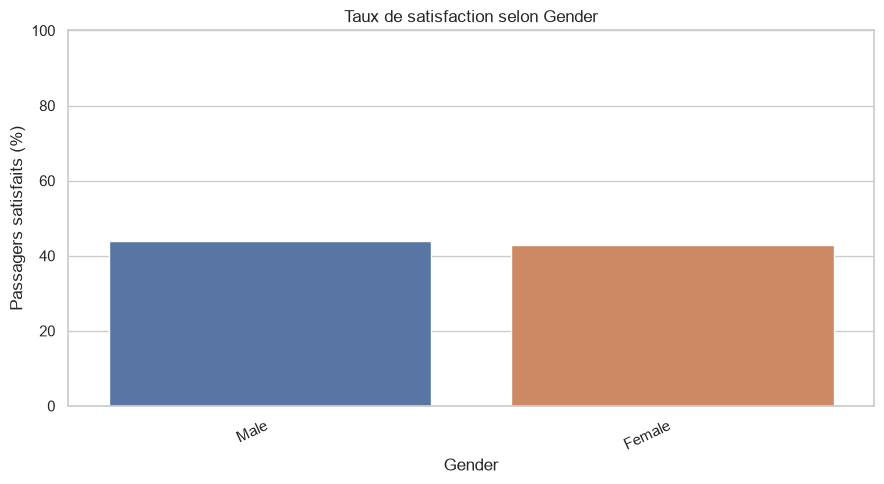


--- Satisfaction selon Customer Type ---


,Customer Type,nombre_passagers,taux_satisfaction
0,Loyal Customer,84923,47.729119
1,disloyal Customer,18981,23.665771


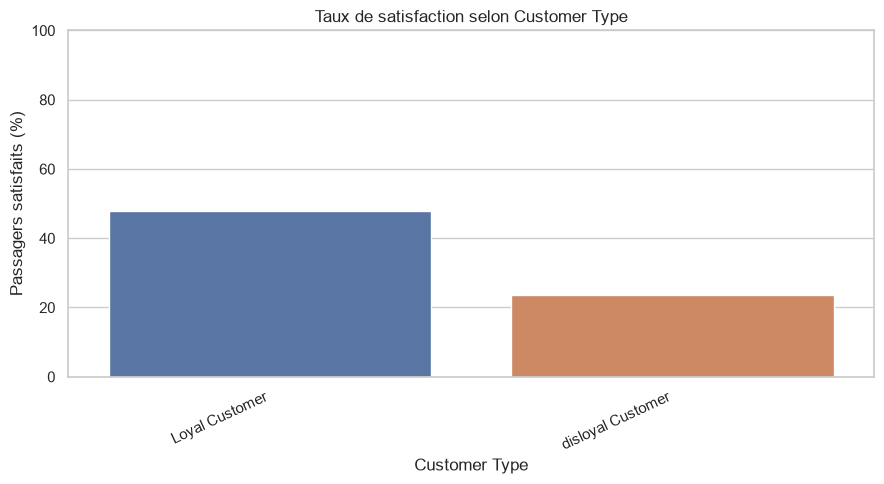


--- Satisfaction selon Type of Travel ---


,Type of Travel,nombre_passagers,taux_satisfaction
0,Business travel,71655,58.259717
1,Personal Travel,32249,10.167757


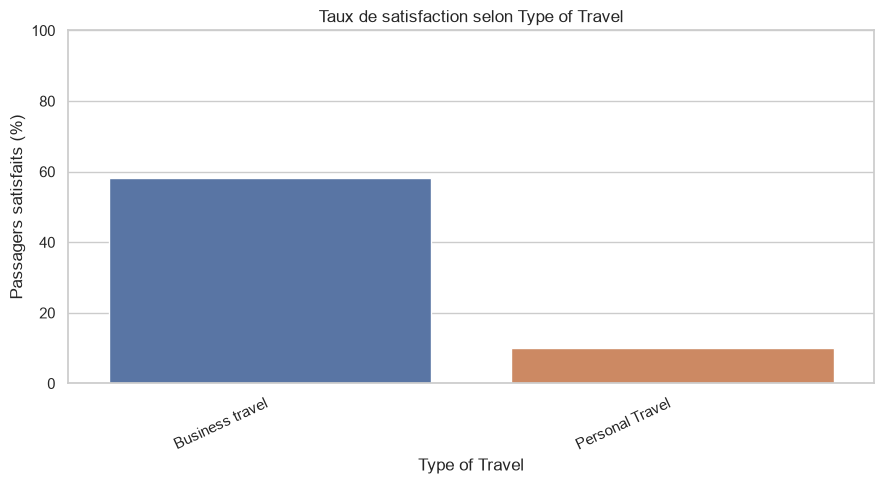


--- Satisfaction selon Class ---


,Class,nombre_passagers,taux_satisfaction
0,Business,49665,69.425148
2,Eco Plus,7494,24.606352
1,Eco,46745,18.613755


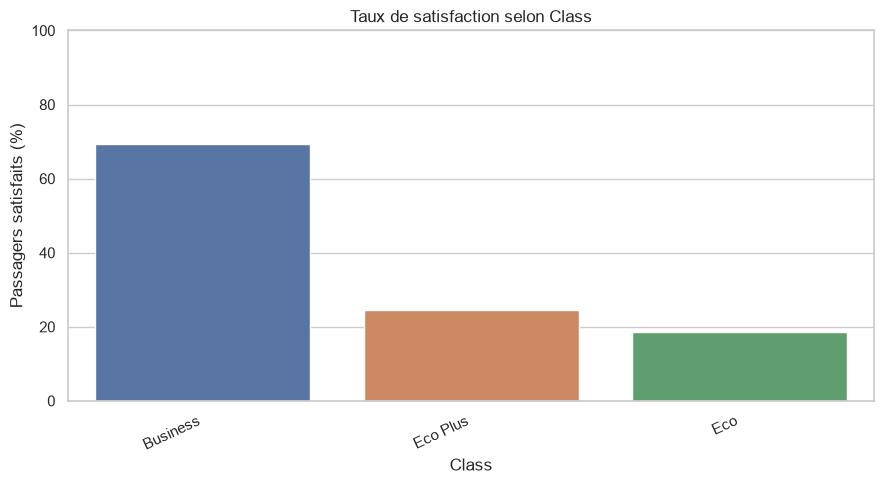

In [32]:
profil_columns = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for colonne in profil_columns:
    print(f"\n--- Satisfaction selon {colonne} ---")
    display(satisfaction_par(colonne))
    graphique_satisfaction(colonne)

## Analyser l'âge
L'âge est numérique : il vaut mieux le regrouper en tranches pour rendre les résultats lisibles.

,age_group,nombre_passagers,taux_satisfaction
3,46-60,29919,57.408336
2,31-45,33252,48.727896
1,19-30,23848,35.411775
4,61+,7976,20.837513
0,0-18,8909,17.274666


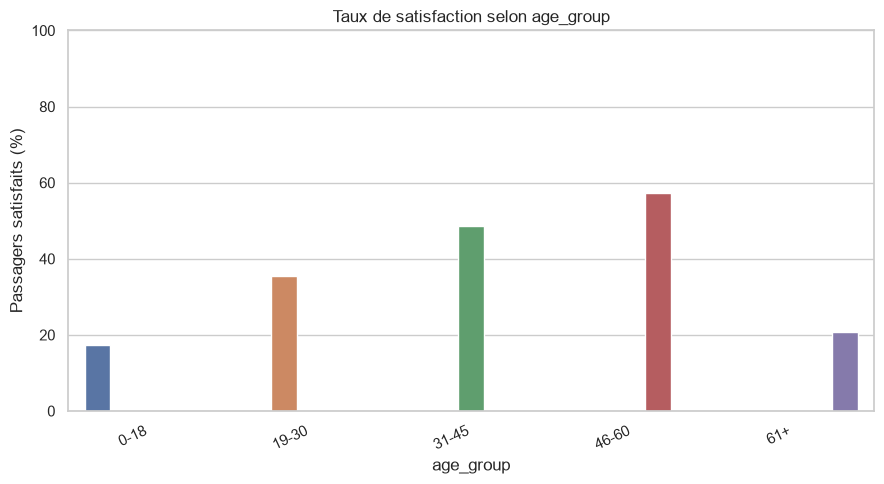

,age_group,nombre_passagers,taux_satisfaction
3,46-60,29919,57.408336
2,31-45,33252,48.727896
1,19-30,23848,35.411775
4,61+,7976,20.837513
0,0-18,8909,17.274666


In [33]:
df["age_group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 30, 45, 60, 120],
    labels=[
        "0-18",
        "19-30",
        "31-45",
        "46-60",
        "61+"
    ],
    include_lowest=True
)

age_results = satisfaction_par("age_group")

display(age_results)
graphique_satisfaction("age_group")

## Analyser les retards

Les retards inconnus resteront manquants et ne seront pas assimilés à des retards nuls. Le tableau permettra de voir si la satisfaction varie selon l'importance du retard.

,delay_group,nombre_passagers,taux_satisfaction
0,Aucun retard,58159,47.279011
1,1-15 min,21800,41.302752
4,NaN,310,41.290323
3,Plus de 60 min,7327,35.717210
2,16-60 min,16308,35.436596


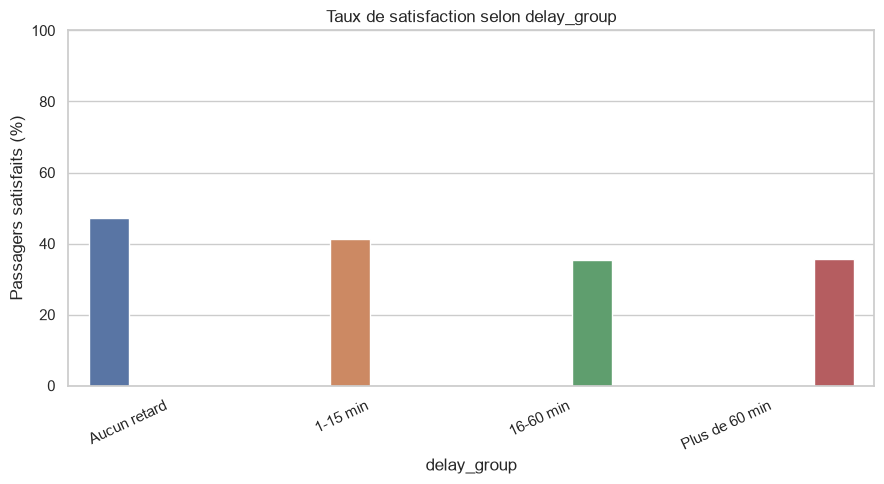

,delay_group,nombre_passagers,taux_satisfaction
0,Aucun retard,58159,47.279011
1,1-15 min,21800,41.302752
4,NaN,310,41.290323
3,Plus de 60 min,7327,35.717210
2,16-60 min,16308,35.436596


In [34]:
df["delay_group"] = pd.cut(
    df["Arrival Delay in Minutes"],
    bins=[-0.01, 0, 15, 60, np.inf],
    labels=[
        "Aucun retard",
        "1-15 min",
        "16-60 min",
        "Plus de 60 min"
    ]
)

delay_results = satisfaction_par("delay_group")

display(delay_results)
graphique_satisfaction("delay_group")

Pour compléter l'analyse, calcule aussi les statistiques descriptives :

In [35]:
df.groupby("satisfaction")[
    [
        "Departure Delay in Minutes",
        "Arrival Delay in Minutes"
    ]
].agg(["count", "median", "mean"]).round(2)

Departure Delay in Minutes                \
                                             count median   mean   
satisfaction                                                       
neutral or dissatisfied                      58879    0.0  16.50   
satisfied                                    45025    0.0  12.61   

                        Arrival Delay in Minutes                
                                           count median   mean  
satisfaction                                                    
neutral or dissatisfied                    58697    0.0  17.13  
satisfied                                  44897    0.0  12.63

### Partie B — Les 14 notes de service
Le jeu de données contient 14 notes, allant de 1 à 5, avec 0 pour une absence de réponse ou un service non applicable. Nous allons donc traiter les zéros comme des valeurs manquantes pour le calcul des notes moyennes, sans supprimer les passagers du dataset.

## Calculer les notes moyennes par satisfaction

In [36]:
rating_columns = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

# Contrôler que les 14 colonnes existent
missing_columns = [
    col for col in rating_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Colonnes de notes manquantes : {missing_columns}"
    )

# Remplacer les zéros par NaN uniquement pour cette analyse
ratings = df[rating_columns].replace(0, np.nan)

# Ajouter la cible pour comparer les deux groupes
ratings["satisfaction"] = df["satisfaction"].values

mean_ratings = ratings.groupby("satisfaction")[rating_columns].mean().T

display(mean_ratings.round(2))

satisfaction,neutral or dissatisfied,satisfied
Inflight wifi service,2.40,3.39
Departure/Arrival time convenient,3.28,3.15
Ease of Online booking,2.61,3.25
Gate location,2.98,2.98
Food and drink,2.96,3.53
Online boarding,2.71,4.15
Seat comfort,3.04,3.97
Inflight entertainment,2.89,3.96
On-board service,3.02,3.86
Leg room service,3.01,3.84


## Mesurer l'écart entre les groupes
L'interprétation est simple :
- Un écart positif élevé signifie que les satisfaits donnent, en moyenne, de meilleures notes à ce service.
- Un écart proche de zéro signifie que les moyennes des deux groupes sont similaires.
- Un écart négatif signifie que la moyenne est plus élevée chez les neutres ou insatisfaits, ce qui mérite une vérification.

In [37]:
rating_comparison = pd.DataFrame({
    "moyenne_satisfaits": mean_ratings["satisfied"],
    "moyenne_neutres_insatisfaits":
        mean_ratings["neutral or dissatisfied"]
})

rating_comparison["ecart"] = (
    rating_comparison["moyenne_satisfaits"]
    - rating_comparison["moyenne_neutres_insatisfaits"]
)

rating_comparison = rating_comparison.sort_values(
    "ecart",
    ascending=False
)

display(rating_comparison.round(2))

,moyenne_satisfaits,moyenne_neutres_insatisfaits,ecart
Online boarding,4.15,2.71,1.45
Inflight entertainment,3.96,2.89,1.07
Inflight wifi service,3.39,2.40,0.99
Seat comfort,3.97,3.04,0.93
On-board service,3.86,3.02,0.84
Leg room service,3.84,3.01,0.83
Cleanliness,3.74,2.94,0.81
Ease of Online booking,3.25,2.61,0.63
Checkin service,3.65,3.04,0.60
Baggage handling,3.97,3.38,0.59


## Visualiser le classement

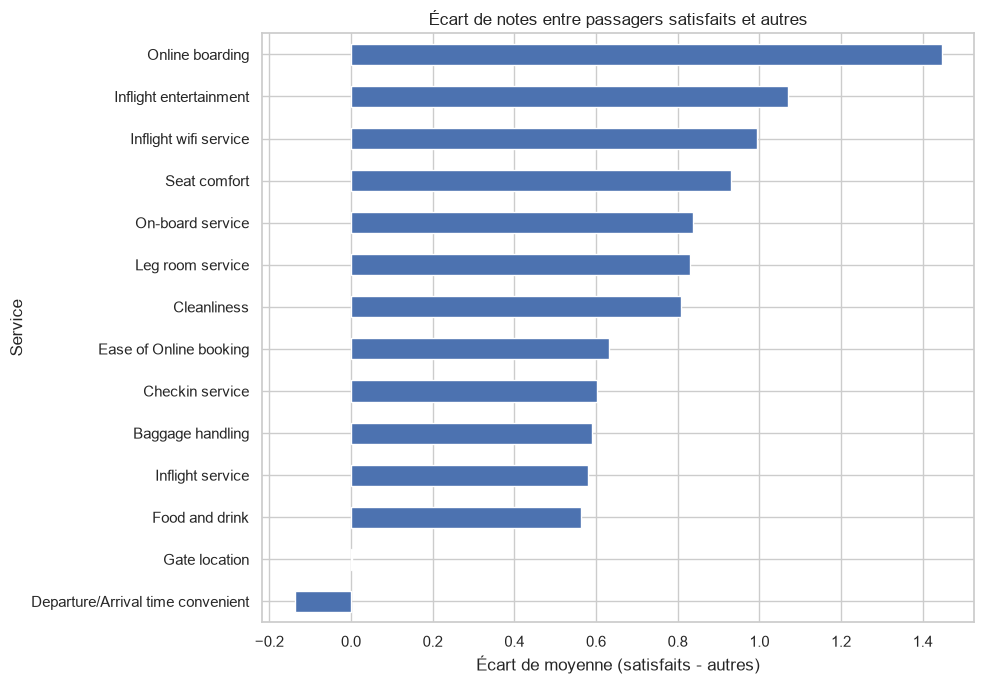

In [38]:
rating_comparison["ecart"].sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Écart de notes entre passagers satisfaits et autres")
plt.xlabel("Écart de moyenne (satisfaits - autres)")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

## Vérifier si les zéros sont fréquents
C'est important : un service peut sembler avoir de bonnes notes simplement parce que les passagers qui l'ont évalué sont un sous-groupe particulier.
Ce tableau permet de repérer les services pour lesquels les non-réponses ou les cas non applicables sont fréquents. Il faut les signaler dans ton analyse.

In [39]:
zero_rate = (
    df[rating_columns].eq(0).mean() * 100
).sort_values(ascending=False)

zero_report = pd.DataFrame({
    "pourcentage_zeros": zero_rate.round(2),
    "nombre_zeros": df[rating_columns].eq(0).sum()
})

display(zero_report)

,pourcentage_zeros,nombre_zeros
Baggage handling,0.00,0
Checkin service,0.00,1
Cleanliness,0.01,12
Departure/Arrival time convenient,5.10,5300
Ease of Online booking,4.32,4487
Food and drink,0.10,107
Gate location,0.00,1
Inflight entertainment,0.01,14
Inflight service,0.00,3
Inflight wifi service,2.99,3103


### Partie C — Mesurer l'importance des facteurs, globalement et par segment
Pour éviter de dire qu'un facteur est « important » simplement parce qu'il présente une grande différence visuelle, je te conseille de produire trois éléments :
1. l'écart de taux de satisfaction ;
2. le nombre de passagers concernés ;
3. une mesure statistique de l'association.
Pour les catégories, on peut calculer le V de Cramér, une mesure d'association comprise entre 0 et 1. Il ne prouve pas qu'une variable cause la satisfaction.

## Fonction pour calculer le V de Cramér
Cette fonction compare une caractéristique catégorielle à la cible satisfaction.

In [40]:
def cramers_v(data, factor, target="satisfaction"):
    table = pd.crosstab(data[factor], data[target])

    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()

    if n == 0:
        return np.nan

    phi2 = chi2 / n
    r, k = table.shape

    # Correction du biais pour les petits échantillons
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(k_corr - 1, r_corr - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominator)

## Classement des facteurs de profil

Tu obtiendras un premier classement des associations entre le profil du passager et sa satisfaction.
Pour les notes de service, le tableau des écarts de moyennes précédent sera utile, mais je te recommande aussi de comparer les distributions ou d'utiliser un test statistique adapté. Ne compare pas directement le V de Cramér d'une variable catégorielle et un écart de notes comme s'il s'agissait de la même unité.

In [41]:
categorical_factors = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class",
    "age_group",
    "delay_group"
]

factor_results = []

for factor in categorical_factors:
    data = df[[factor, "satisfaction"]].dropna()

    factor_results.append({
        "facteur": factor,
        "V_de_Cramer": cramers_v(data, factor),
        "nombre_passagers": len(data),
        "modalites": data[factor].nunique()
    })

factor_importance = pd.DataFrame(factor_results)

factor_importance = factor_importance.sort_values(
    "V_de_Cramer",
    ascending=False
)

display(factor_importance.round(3))

,facteur,V_de_Cramer,nombre_passagers,modalites
3,Class,0.505,103904,3
2,Type of Travel,0.449,103904,2
4,age_group,0.269,103904,5
1,Customer Type,0.188,103904,2
5,delay_group,0.098,103594,4
0,Gender,0.012,103904,2


## Examiner les facteurs par segment
Par exemple, nous pouvons regarder les notes de service séparément pour les voyages professionnels et personnels.

In [42]:
segment_column = "Type of Travel"

segment_results = []

for segment, group in df.groupby(segment_column, observed=True):
    segment_ratings = (
        group[rating_columns]
        .replace(0, np.nan)
        .groupby(group["satisfaction"])
        .mean()
    )

    if (
        "satisfied" in segment_ratings.index
        and "neutral or dissatisfied" in segment_ratings.index
    ):
        gaps = (
            segment_ratings.loc["satisfied"]
            - segment_ratings.loc["neutral or dissatisfied"]
        )

        for service, gap in gaps.items():
            segment_results.append({
                "segment": segment,
                "service": service,
                "ecart_de_notes": gap,
                "nombre_passagers": len(group)
            })

segment_rating_gaps = pd.DataFrame(segment_results)

display(
    segment_rating_gaps.sort_values(
        ["segment", "ecart_de_notes"],
        ascending=[True, False]
    ).round(2)
)

,segment,service,ecart_de_notes,nombre_passagers
5,Business travel,Online boarding,1.54,71655
7,Business travel,Inflight entertainment,1.31,71655
6,Business travel,Seat comfort,1.14,71655
8,Business travel,On-board service,1.13,71655
13,Business travel,Cleanliness,1.05,71655
9,Business travel,Leg room service,0.93,71655
0,Business travel,Inflight wifi service,0.92,71655
11,Business travel,Checkin service,0.91,71655
10,Business travel,Baggage handling,0.82,71655
12,Business travel,Inflight service,0.81,71655


### Partie D — Le tableau « associé / actionnable / causal ? »
C'est le tableau qui relie tes analyses statistiques aux décisions de la compagnie.
La distinction à faire est la suivante :
- Associé ? Les données montrent-elles une relation mesurable avec la satisfaction ?
- Actionnable ? La compagnie peut-elle modifier ce facteur par une décision, un investissement ou une amélioration de service ?
- Causal ? Les analyses permettent-elles d'affirmer que modifier ce facteur entraînera une hausse de la satisfaction ?
Avec des données observationnelles issues d'un questionnaire, une association ne suffit pas à établir la causalité.

## Créer un tableau métier à compléter
Voici un modèle de départ. Les niveaux d'association doivent être complétés à partir des résultats de tes cellules précédentes.

Ces lignes sont des hypothèses de travail, pas des conclusions tirées de tes données. Il faudra remplacer « À vérifier » par une conclusion étayée par les résultats obtenus. Tu peux ajouter des facteurs parmi les 14 services.
Par exemple, si le Wi-Fi présente un grand écart de notes entre les deux groupes, tu pourras écrire qu'il est associé à la satisfaction. Tu ne pourras pas affirmer, sur cette seule base, qu'investir dans le Wi-Fi augmentera nécessairement la satisfaction.

In [43]:
business_factors = pd.DataFrame([
    {
        "facteur": "Wi-Fi en vol",
        "associe": "À vérifier dans les résultats",
        "actionnable": "Oui, via la qualité et la couverture",
        "causal": "Non démontré",
        "action_possible": "Améliorer la disponibilité et la stabilité"
    },
    {
        "facteur": "Embarquement en ligne",
        "associe": "À vérifier dans les résultats",
        "actionnable": "Oui, via le parcours numérique",
        "causal": "Non démontré",
        "action_possible": "Simplifier le parcours d'enregistrement"
    },
    {
        "facteur": "Confort du siège",
        "associe": "À vérifier dans les résultats",
        "actionnable": "Oui, avec des contraintes de coût",
        "causal": "Non démontré",
        "action_possible": "Étudier les améliorations de confort"
    },
    {
        "facteur": "Retard à l'arrivée",
        "associe": "À vérifier dans les résultats",
        "actionnable": "Partiellement",
        "causal": "Non démontré par cette analyse",
        "action_possible": "Améliorer la gestion des perturbations"
    },
    {
        "facteur": "Classe de voyage",
        "associe": "À vérifier dans les résultats",
        "actionnable": "Partiellement",
        "causal": "Non démontré",
        "action_possible": "Adapter les services aux besoins des segments"
    },
    {
        "facteur": "Type de voyage",
        "associe": "À vérifier dans les résultats",
        "actionnable": "Pas directement",
        "causal": "Non démontré",
        "action_possible": "Adapter les services au motif du voyage"
    }
])

display(business_factors)

,facteur,associe,actionnable,causal,action_possible
0,Wi-Fi en vol,À vérifier dans les résultats,"Oui, via la qualité et la couverture",Non démontré,Améliorer la disponibilité et la stabilité
1,Embarquement en ligne,À vérifier dans les résultats,"Oui, via le parcours numérique",Non démontré,Simplifier le parcours d'enregistrement
2,Confort du siège,À vérifier dans les résultats,"Oui, avec des contraintes de coût",Non démontré,Étudier les améliorations de confort
3,Retard à l'arrivée,À vérifier dans les résultats,Partiellement,Non démontré par cette analyse,Améliorer la gestion des perturbations
4,Classe de voyage,À vérifier dans les résultats,Partiellement,Non démontré,Adapter les services aux besoins des segments
5,Type de voyage,À vérifier dans les résultats,Pas directement,Non démontré,Adapter les services au motif du voyage
